# Практическая работа №2: Программирование на R

## Задание №1

1. Создать таблицу данных "Социологический опрос" из 6 случаев и 4 переменных с помощью конструкции `data.frame()` и вывести полученную таблицу данных. Имена переменных задать следующие: `name` (ФИО), `sex` (Пол), `age` (Возраст), `education` (Образование), `income` (Доход):

|        ФИО        |   Пол  | Возраст | Образование | Доход |
|:-----------------:|:------:|:-------:|:-----------:|:-----:|
|     John Davis    |  Male  |    21   |  Secondary  |  125  |
|  Angela Williams  | Female |    23   |    Higher   |  345  |
| Janice Markhammer | Female |    40   |             |   50  |
|  Bullwinkle Moose |  Male  |    35   |  Secondary  |  399  |
|    Mary Rayburn   | Female |    18   |  Secondary  |  136  |
|     Greg Knox     |  Male  |    20   |    Higher   |  120  |

*Можно заметить, что одно значение пропущено. Вспомните, как правильно обозначаются такие объекты в таблицах данных.*

In [33]:
respondents <- data.frame(
    name = c("John Davis", "Angela Williams", "Janice Markhammer", "Bullwinkle Moose", "Mary Rayburn", "Greg Knox"),
    sex = c("Male", "Female", "Female", "Male", "Female", "Male"),
    age = c(21, 23, 40, 35, 18, 20),
    education = c("Secondary", "Higher", NA_character_, "Secondary", "Secondary", "Higher"),
    income = c(125, 345, 50, 399, 136, 120)
)
respondents

name,sex,age,education,income
<chr>,<chr>,<dbl>,<chr>,<dbl>
John Davis,Male,21,Secondary,125
Angela Williams,Female,23,Higher,345
Janice Markhammer,Female,40,NA,50
Bullwinkle Moose,Male,35,Secondary,399
Mary Rayburn,Female,18,Secondary,136
Greg Knox,Male,20,Higher,120


2. Переменные "Пол" и "Образование" в таблице данных представить как факторные. Причём для "Образование" необходимо установить следующий порядок: `1 = Secondary`, `2 = Higher`. Проверить, что эти переменные действительно факторные c помощью соответствующих функций. Вывести таблицу данных.

In [34]:
respondents$sex <- factor(respondents$sex)
respondents$education <- factor(
  respondents$education,
  levels = c("Secondary", "Higher"),
  ordered = TRUE
)

is.factor(respondents$sex)
is.factor(respondents$education)
is.ordered(respondents$education)
levels(respondents$education)

respondents

[1] TRUE

[1] TRUE

[1] TRUE

[1] "Secondary" "Higher"

name,sex,age,education,income
<chr>,<fct>,<dbl>,<ord>,<dbl>
John Davis,Male,21,Secondary,125
Angela Williams,Female,23,Higher,345
Janice Markhammer,Female,40,NA,50
Bullwinkle Moose,Male,35,Secondary,399
Mary Rayburn,Female,18,Secondary,136
Greg Knox,Male,20,Higher,120


3. Вывести резюме по каждому предикту таблицы данных. Вывести информацию о типе каждой переменной.

In [35]:
summary(respondents)
str(respondents)
sapply(respondents, class)

        name        sex         age            education     income     
 Length   : 6   Female:3   Min.   :18.00   Secondary:3   Min.   : 50.0  
 N.unique : 6   Male  :3   1st Qu.:20.25   Higher   :2   1st Qu.:121.2  
 N.blank  : 0              Median :22.00   NAs      :1   Median :130.5  
 Min.nchar: 9              Mean   :26.17                 Mean   :195.8  
 Max.nchar:17              3rd Qu.:32.00                 3rd Qu.:292.8  
                           Max.   :40.00                 Max.   :399.0  

'data.frame':	6 obs. of  5 variables:
 $ name     : chr  "John Davis" "Angela Williams" "Janice Markhammer" "Bullwinkle Moose" ...
 $ sex      : Factor w/ 2 levels "Female","Male": 2 1 1 2 1 2
 $ age      : num  21 23 40 35 18 20
 $ education: Ord.factor w/ 2 levels "Secondary"<"Higher": 1 2 NA 1 1 2
 $ income   : num  125 345 50 399 136 120


$name
[1] "character"

$sex
[1] "factor"

$age
[1] "numeric"

$education
[1] "ordered" "factor" 

$income
[1] "numeric"

4. Добавить в таблицу новую переменную `income_20` (Доход\_20), значения которой равны Доход + премия в размере 20% от Дохода. Вывести таблицу данных.

In [36]:
respondents$income_20 <- respondents$income * 1.2
respondents

name,sex,age,education,income,income_20
<chr>,<fct>,<dbl>,<ord>,<dbl>,<dbl>
John Davis,Male,21,Secondary,125,150.0
Angela Williams,Female,23,Higher,345,414.0
Janice Markhammer,Female,40,NA,50,60.0
Bullwinkle Moose,Male,35,Secondary,399,478.8
Mary Rayburn,Female,18,Secondary,136,163.2
Greg Knox,Male,20,Higher,120,144.0


5. Рассчитать среднее значение Дохода.

In [37]:
mean_income <- mean(respondents$income, na.rm = TRUE)
mean_income

[1] 195.8333

6. Используя инструменты R построить столбчатые диаграммы для Возраста и Дохода. Диаграммы изобразить на одной строке.

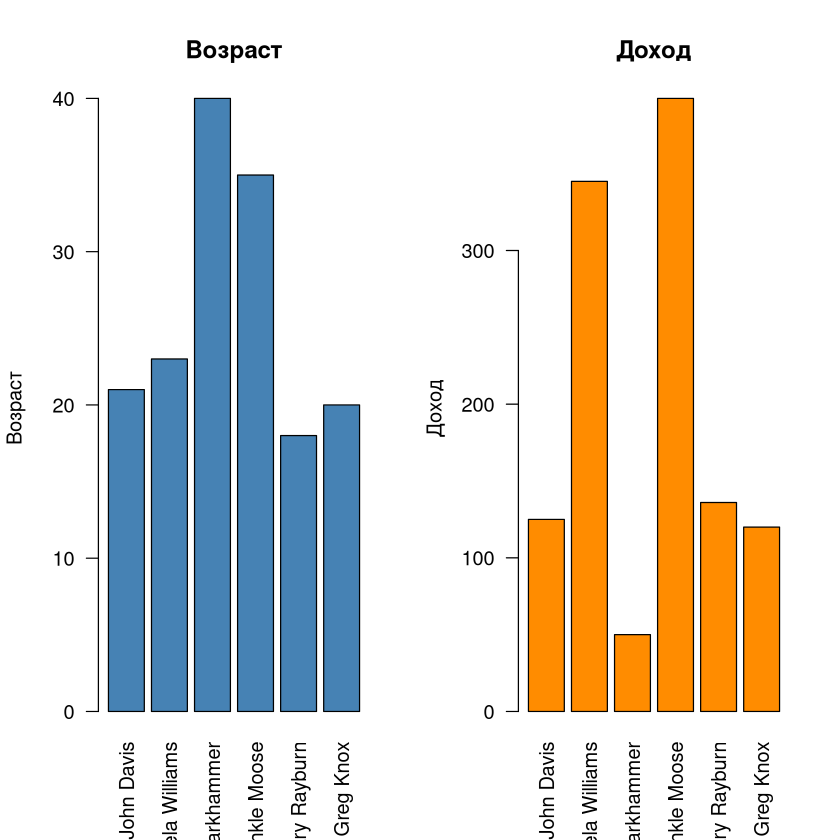

In [39]:
par(mfrow = c(1, 2))
barplot(
    respondents$age, 
    names.arg = respondents$name, 
    main = "Возраст", 
    col = "steelblue", 
    las = 2, 
    ylab = "Возраст"
)
barplot(
    respondents$income, 
    names.arg = respondents$name, 
    main = "Доход", 
    col = "darkorange", 
    las = 2, 
    ylab = "Доход"
)
par(mfrow = c(1, 1))

7. Добавить в таблицу новую переменную `income_S` (Доход\_С), значения которой равны Доход + Доход\_20. Вывести таблицу данных.

In [40]:
respondents$income_S <- respondents$income + respondents$income_20
respondents

name,sex,age,education,income,income_20,income_S
<chr>,<fct>,<dbl>,<ord>,<dbl>,<dbl>,<dbl>
John Davis,Male,21,Secondary,125,150.0,275.0
Angela Williams,Female,23,Higher,345,414.0,759.0
Janice Markhammer,Female,40,NA,50,60.0,110.0
Bullwinkle Moose,Male,35,Secondary,399,478.8,877.8
Mary Rayburn,Female,18,Secondary,136,163.2,299.2
Greg Knox,Male,20,Higher,120,144.0,264.0


8. Добавить новую переменную `income_M` (Доход\_М). Необходимо найти максимальный доход и для каждого респондента определить, сколько процентов от максимального дохода составляет его доход. Вывести таблицу данных.

In [42]:
respondents$income_M <- respondents$income / max(respondents$income, na.rm = TRUE) * 100
respondents

name,sex,age,education,income,income_20,income_S,income_M
<chr>,<fct>,<dbl>,<ord>,<dbl>,<dbl>,<dbl>,<dbl>
John Davis,Male,21,Secondary,125,150.0,275.0,31.32832
Angela Williams,Female,23,Higher,345,414.0,759.0,86.46617
Janice Markhammer,Female,40,NA,50,60.0,110.0,12.53133
Bullwinkle Moose,Male,35,Secondary,399,478.8,877.8,100.00000
Mary Rayburn,Female,18,Secondary,136,163.2,299.2,34.08521
Greg Knox,Male,20,Higher,120,144.0,264.0,30.07519


9. Рассчитать среднее значение дохода в зависимости от пола.

In [43]:
aggregate(income ~ sex, data = respondents, FUN = mean)

sex,income
<fct>,<dbl>
Female,177.0000
Male,214.6667


10. Удалить переменную `income_20`. Вывести обновлённую таблицу данных.

In [44]:
respondents$income_20 <- NULL
respondents

name,sex,age,education,income,income_S,income_M
<chr>,<fct>,<dbl>,<ord>,<dbl>,<dbl>,<dbl>
John Davis,Male,21,Secondary,125,275.0,31.32832
Angela Williams,Female,23,Higher,345,759.0,86.46617
Janice Markhammer,Female,40,NA,50,110.0,12.53133
Bullwinkle Moose,Male,35,Secondary,399,877.8,100.00000
Mary Rayburn,Female,18,Secondary,136,299.2,34.08521
Greg Knox,Male,20,Higher,120,264.0,30.07519


11. *(Дополнительное задание)* Удалить строки, которые содержат пропущенные значения (представьте, что у вас огромная таблица данных и вы не знаете в какой строке и какая переменная пустая).

In [45]:
respondents_clean <- na.omit(respondents)
respondents_clean

,name,sex,age,education,income,income_S,income_M
,<chr>,<fct>,<dbl>,<ord>,<dbl>,<dbl>,<dbl>
1,John Davis,Male,21,Secondary,125,275.0,31.32832
2,Angela Williams,Female,23,Higher,345,759.0,86.46617
4,Bullwinkle Moose,Male,35,Secondary,399,877.8,100.00000
5,Mary Rayburn,Female,18,Secondary,136,299.2,34.08521
6,Greg Knox,Male,20,Higher,120,264.0,30.07519


# Задание №2

1. Составить таблицу $ 1000 \times 3 $, содержащую в качестве первой переменной значения $ x_i \in [0, 2\pi] $ ($ x_i $ изменяется с постоянным шагом), в качестве второй – значения $ \sin x_i $, в качестве третьей – значения $ \sin(x_i) + \xi $, где $ \xi \sim \mathcal N(0, 0.005) $.

In [58]:
set.seed(123)

n <- 1000
x <- seq(0, 2 * pi, length.out = n)
sin_x <- sin(x)
sin_noisy = sin_x + rnorm(n, mean = 0, sd = sqrt(0.005))


df2 <- data.frame(
  x = x,
  sin_x = sin_x,
  sin_noisy = sin_noisy
)

nrow(df2)
head(df2)
tail(df2)

[1] 1000

,x,sin_x,sin_noisy
,<dbl>,<dbl>,<dbl>
1,0.000000000,0.000000000,-0.039631613
2,0.006289475,0.006289433,-0.009986573
3,0.012578950,0.012578618,0.122795940
4,0.018868424,0.018867305,0.023853001
5,0.025157899,0.025155245,0.034297269
6,0.031447374,0.031442191,0.152715599


,x,sin_x,sin_noisy
,<dbl>,<dbl>,<dbl>
995,6.251738,-3.144219e-02,-0.009293572
996,6.258027,-2.515525e-02,-0.031517453
997,6.264317,-1.886730e-02,0.056829610
998,6.270606,-1.257862e-02,-0.108115842
999,6.276896,-6.289433e-03,-0.043244014
1000,6.283185,-2.449294e-16,-0.017620442


2. Создать новую таблицу данных, которые будут содержать только первые 100 строк и последние 50 строк таблицы из п. 1.

In [88]:
df_sub <- rbind(head(df2, 100), tail(df2, 50))
nrow(df_sub)
head(df_sub)
tail(df_sub)

[1] 150

,x,sin_x,sin_noisy
,<dbl>,<dbl>,<dbl>
1,0.000000000,0.000000000,-0.039631613
2,0.006289475,0.006289433,-0.009986573
3,0.012578950,0.012578618,0.122795940
4,0.018868424,0.018867305,0.023853001
5,0.025157899,0.025155245,0.034297269
6,0.031447374,0.031442191,0.152715599


,x,sin_x,sin_noisy
,<dbl>,<dbl>,<dbl>
995,6.251738,-3.144219e-02,-0.009293572
996,6.258027,-2.515525e-02,-0.031517453
997,6.264317,-1.886730e-02,0.056829610
998,6.270606,-1.257862e-02,-0.108115842
999,6.276896,-6.289433e-03,-0.043244014
1000,6.283185,-2.449294e-16,-0.017620442


3. Используя инструменты R вывести первые 5 строчек таблицы данных из п. 2.

In [60]:
head(df_sub, 5)

,x,sin_x,sin_noisy
,<dbl>,<dbl>,<dbl>
1,0.000000000,0.000000000,-0.039631613
2,0.006289475,0.006289433,-0.009986573
3,0.012578950,0.012578618,0.122795940
4,0.018868424,0.018867305,0.023853001
5,0.025157899,0.025155245,0.034297269


4. Используя инструменты R вывести последние 10 строчек таблицы данных из п. 2.

In [61]:
tail(df_sub, 10)

,x,sin_x,sin_noisy
,<dbl>,<dbl>,<dbl>
991,6.226580,-5.657505e-02,-0.008791431
992,6.232870,-5.029457e-02,-0.126252448
993,6.239159,-4.401210e-02,-0.011868597
994,6.245448,-3.772789e-02,-0.052810985
995,6.251738,-3.144219e-02,-0.009293572
996,6.258027,-2.515525e-02,-0.031517453
997,6.264317,-1.886730e-02,0.056829610
998,6.270606,-1.257862e-02,-0.108115842
999,6.276896,-6.289433e-03,-0.043244014


5. Нарисовать 2 синусоиды на одном графике, используя данные из п. 1. Добавьте заголовок графика, сетку и легенду, подпишите оси. Графики нарисуйте разными цветами и разным типом линий.

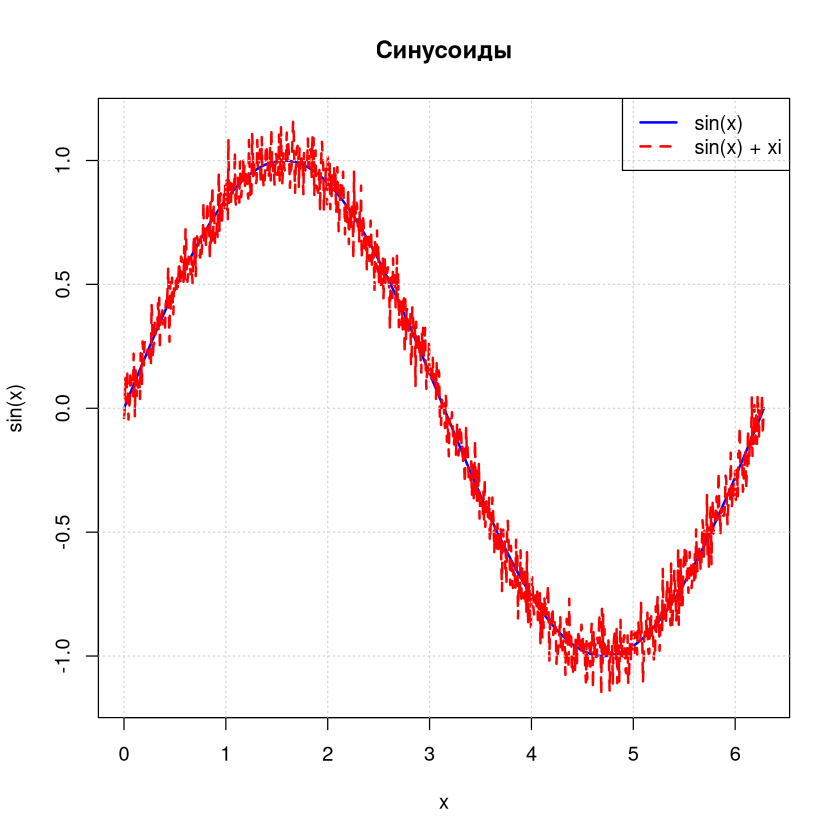

In [66]:
plot(
  df2$x, df2$sin_x,
  type = "l", 
  col = "blue", 
  lty = 1, 
  lwd = 2,
  main = "Синусоиды",
  xlab = "x",
  ylab = "sin(x)",
  ylim = range(c(df2$sin_x, df2$sin_noisy))
)

lines(
  df2$x, df2$sin_noisy,
  col = "red", 
  lty = 2, 
  lwd = 2
)

grid()
legend(
  "topright",
  legend = c("sin(x)", "sin(x) + xi"),
  col = c("blue", "red"),
  lty = c(1, 2),
  lwd = 2
)

6. Используя данные из п. 1 нарисовать 2 синусоиды в одном графическом окне, **но на разных графиках** (*если непонятно – напишите преподавателю в ЛК, он объяснит*). Добавьте заголовки и сетку, подпишите оси. Графики нарисуйте разными цветами и разным типом линий.

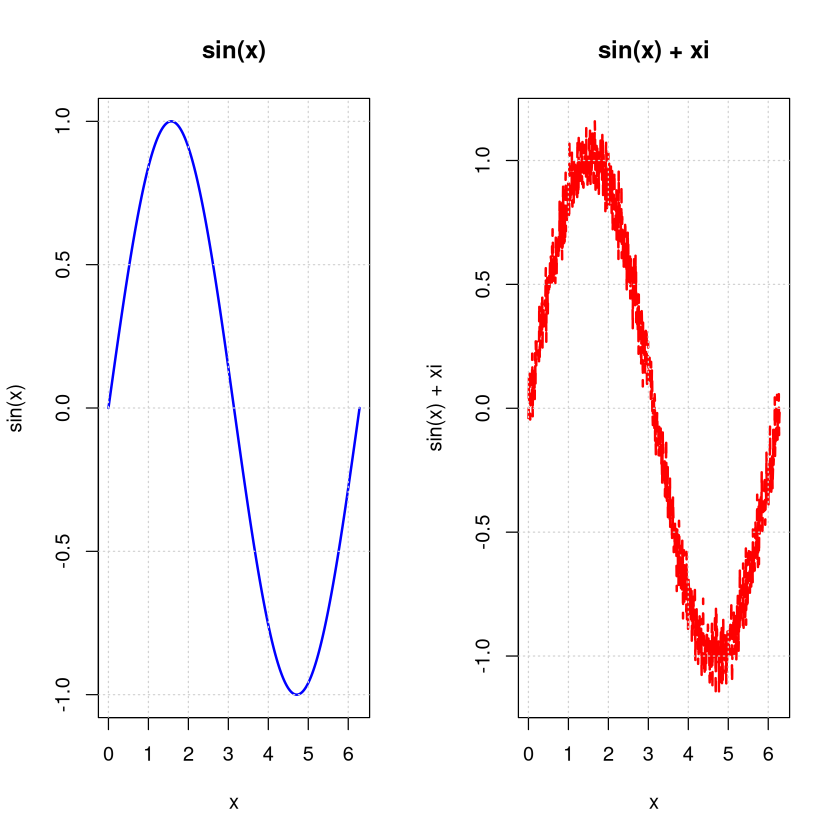

In [67]:
par(mfrow = c(1, 2))

plot(
  df2$x, df2$sin_x,
  type = "l", 
  col = "blue", 
  lty = 1, 
  lwd = 2,
  main = "sin(x)",
  xlab = "x",
  ylab = "sin(x)"
)
grid()

plot(
  df2$x, df2$sin_noisy,
  type = "l", 
  col = "red", 
  lty = 2, 
  lwd = 2,
  main = "sin(x) + xi",
  xlab = "x",
  ylab = "sin(x) + xi"
)
grid()

par(mfrow = c(1, 1))

## Задание №3
По возможности, не используйте в данном задании циклы.

1. Функция `arab2rome()`. На вход подаётся вектор `a` из натуральных чисел от 1 до 10. Необходимо вернуть вектор той же длины, элементы которого содержат в себе римские цифры.

e.g.: **Input**: `c(1, 1, 2, 3, 5, 8)`. **Output**: `c("I", "I", "II", "III", "V", "VIII")`

In [68]:
arab2rome <- function(a) {
    rom <- c("I", "II", "III", "IV", "V", "VI", "VII", "VIII", "IX", "X")
    rom[a]
}

In [ ]:
arab2rome(c(1, 2, 3, 4, 5, 6, 7, 8, 9, 10))
arab2rome(c(1, 1, 2, 3, 5, 8))

[1] "I"    "II"   "III"  "IV"   "V"    "VI"   "VII"  "VIII" "IX"   "X"

[1] "I"    "I"    "II"   "III"  "V"    "VIII"

2. Функция `palindrome()`. На вход поступает строка `str`, которую надо проверить, является ли она палиндромом. В случае положительного или отрицательного ответа выведете соответствующее сообщение на экран.

e.g.1: **Input**: `'"Not New York", - Roy went on'`. **Output**: `"This string is a palindrome!"`

e.g.2: **Input**: `"Hello, world!"`. **Output**: `"This string is not a palindrome!"`

In [73]:
palindrome <- function(str) {
    s <- tolower(gsub("[^[:alnum:]]", "", str))
    rev_s <- paste(rev(strsplit(s, "")[[1]]), collapse = "")
    
    if (identical(s, rev_s)) {
        cat("This string is a palindrome!\n")
    } else {
        cat("This string is not a palindrome!\n")
    }
}

In [74]:
palindrome('"Not New York", - Roy went on')
palindrome("Hello, world!")

This string is a palindrome!
This string is not a palindrome!


3. Функция `spiral()`. Дано натуральное число `n`, целое неотрицательное число `k` и логическое значение `cw`. Необходимо построить квадратичную матрицу-спираль из элементов от 1 до $ n^2 $, где параметр ``cw`` отвечает за направление спирали: `cw == TRUE` – направление по часовой стрелке, `cw == FALSE` (по умолчанию) – направление против часовой стрелки. Параметр `k` отвечает за начальное положение спирали. Ниже представлены примеры для `n = 4`:
  * $ k = 0, 4, 8, \dots $; `cw == TRUE`: $$ \begin{pmatrix} 1 & 2 & 3 & 4 \\ 12 & 13 & 14 & 5 \\ 11 & 16 & 15 & 6 \\ 10 & 9 & 8 & 7 \end{pmatrix} $$
  * $ k = 0, 4, 8, \dots $; `cw == FALSE`: $$ \begin{pmatrix} 1 & 12 & 11 & 10 \\ 2 & 13 & 16 & 9 \\ 3 & 14 & 15 & 8 \\ 4 & 5 & 6 & 7 \end{pmatrix} $$
  * $ k = 1, 5, 9, \dots $; `cw == TRUE`: $$ \begin{pmatrix} 10 & 11 & 12 & 1 \\ 9 & 16 & 13 & 2 \\ 8 & 15 & 14 & 3 \\ 7 & 6 & 5 & 4 \end{pmatrix} $$
  * $ k = 1, 5, 9, \dots $; `cw == FALSE`: $$ \begin{pmatrix} 4 & 3 & 2 & 1 \\ 5 & 14 & 13 & 12 \\ 6 & 15 & 16 & 11 \\ 7 & 8 & 9 & 10 \end{pmatrix} $$
  * $ k = 2, 6, 10, \dots $; `cw == TRUE`: $$ \begin{pmatrix} 7 & 8 & 9 & 10 \\ 6 & 15 & 16 & 11 \\ 5 & 14 & 13 & 12 \\ 4 & 3 & 2 & 1 \end{pmatrix} $$
  * $ k = 2, 6, 10, \dots $; `cw == FALSE`: $$ \begin{pmatrix} 7 & 6 & 5 & 4 \\ 8 & 15 & 14 & 3 \\ 9 & 16 & 13 & 2 \\ 10 & 11 & 12 & 1 \end{pmatrix} $$
  * $ k = 3, 7, 11, \dots $; `cw == TRUE`: $$ \begin{pmatrix} 4 & 5 & 6 & 7 \\ 3 & 14 & 15 & 8 \\ 2 & 13 & 16 & 9 \\ 1 & 12 & 11 & 10 \end{pmatrix} $$
  * $ k = 3, 7, 11, \dots $; `cw == FALSE`: $$ \begin{pmatrix} 10 & 9 & 8 & 7 \\ 11 & 16 & 15 & 6 \\ 12 & 13 & 14 & 5 \\ 1 & 2 & 3 & 4 \end{pmatrix} $$

In [90]:
spiral <- function(n, k, cw = FALSE) {
    layer_coords <- function(layer) {
        top_row <- layer + 1
        bottom_row <- n - layer
        left_col <- layer + 1
        right_col <- n - layer
        
        if (top_row == bottom_row && left_col == right_col) {
            return(cbind(top_row, left_col))
        }
        
        top_side <- cbind(top_row, left_col:right_col)
        right_side <- cbind((top_row + 1):bottom_row, right_col)
        bottom_side <- cbind(bottom_row, (right_col - 1):left_col)
        left_side <- if (bottom_row - 1 >= top_row + 1) cbind((bottom_row - 1):(top_row + 1), left_col) else NULL
        
        rbind(top_side, right_side, bottom_side, left_side)
    }

    rotate_clockwise <- function(mat) {
        t(mat[nrow(mat):1, , drop = FALSE])
    }

    rotate_n <- function(mat, times) {
        if (times == 0) return(mat)
        rotate_n(rotate_clockwise(mat), times - 1)
    }


    layer_ids   <- 0:floor((n - 1) / 2)
    cell_coords <- do.call(rbind, lapply(layer_ids, layer_coords))
    
    spiral_matrix <- matrix(0, n, n)
    spiral_matrix[cell_coords] <- seq_len(n^2)
    
    if (!cw) {
        spiral_matrix <- t(spiral_matrix)
    }
    
    turns <- k %% 4
    spiral_matrix <- rotate_n(spiral_matrix, turns)
    
    spiral_matrix
}

In [91]:
spiral(4, 0, TRUE)
spiral(4, 4, FALSE)
spiral(4, 5, TRUE)
spiral(4, 1, FALSE)
spiral(4, 2, TRUE)
spiral(4, 6, FALSE)
spiral(4, 7, TRUE)
spiral(4, 3, FALSE)

1,2,3,4
12,13,14,5
11,16,15,6
10,9,8,7


1,12,11,10
2,13,16,9
3,14,15,8
4,5,6,7


10,11,12,1
9,16,13,2
8,15,14,3
7,6,5,4


4,3,2,1
5,14,13,12
6,15,16,11
7,8,9,10


7,8,9,10
6,15,16,11
5,14,13,12
4,3,2,1


7,6,5,4
8,15,14,3
9,16,13,2
10,11,12,1


4,5,6,7
3,14,15,8
2,13,16,9
1,12,11,10


10,9,8,7
11,16,15,6
12,13,14,5
1,2,3,4
